# UserKNN: sensibilidad y evaluación reproducible

**Equipo:** Grupo 18 (eight nine)  
**Integrantes:** Jorge Cartagena y Santiago Valenzuela  
**Uso de IA:** registro y enlaces en [`USO_IA.md`](../USO_IA.md).

Se comparan Pearson y MSD con seis tamaños de vecindario. El modelo se entrena únicamente con `train.csv`; se selecciona la configuración de menor RMSE en `validation.csv` usando precisión completa. El MAE tiene su propia configuración mínima, que también se conserva. Esta validación se usa para desarrollar el modelo: no constituye un test independiente.

In [1]:
from pathlib import Path
import sys

for location in (Path.cwd(), *Path.cwd().parents):
    candidate = location if (location / 'tarea_01').is_dir() else location / 'recsys_tareas'
    if (candidate / 'tarea_01' / 'general_experiments.py').is_file():
        REPO_ROOT = candidate
        break
else:
    raise FileNotFoundError('No se encontró la raíz de recsys_tareas.')
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import pandas as pd
from tarea_01.general_experiments import run_user_knn, plot_user_sensitivity

TASK_DIR = REPO_ROOT / 'tarea_01'
DATASET_DIR = TASK_DIR / 'dataset'
RESULTS_DIR = TASK_DIR / 'informe_assets' / 'data'
FIGURES_DIR = TASK_DIR / 'informe_assets'
SEED = 42
N_NEGATIVES = 100

## Grilla y selección

Para cada similitud, la matriz usuario–usuario se calcula una sola vez; cambiar `k` solo cambia cuántos vecinos se consideran al predecir. Así se conserva exactamente la formulación `KNNBasic`, con `min_k=1`, y se evita repetir ese cálculo. La selección de RMSE no se reemplaza por una constante escrita a mano.

In [2]:
experiment = run_user_knn(
    dataset_dir=DATASET_DIR, output_dir=RESULTS_DIR,
    k_values=(5, 10, 30, 50, 70, 100), similarities=('pearson', 'msd'),
    seed=SEED, n_negatives=N_NEGATIVES,
)
sensitivity = experiment['sensitivity']
sensitivity[['similarity', 'k_neighbors', 'RMSE', 'MAE', 'is_selected_rmse', 'is_selected_mae']]

,similarity,k_neighbors,RMSE,MAE,is_selected_rmse,is_selected_mae
0,pearson,5,1.018683,0.574448,False,False
1,pearson,10,1.015664,0.573821,False,False
2,pearson,30,1.015143,0.573759,False,False
3,pearson,50,1.015143,0.573771,False,False
4,pearson,70,1.015143,0.573770,False,False
5,pearson,100,1.015143,0.573770,False,False
6,msd,5,0.964749,0.485093,False,True
7,msd,10,0.945043,0.492894,False,False
8,msd,30,0.937588,0.503378,False,False
9,msd,50,0.936937,0.505746,False,False


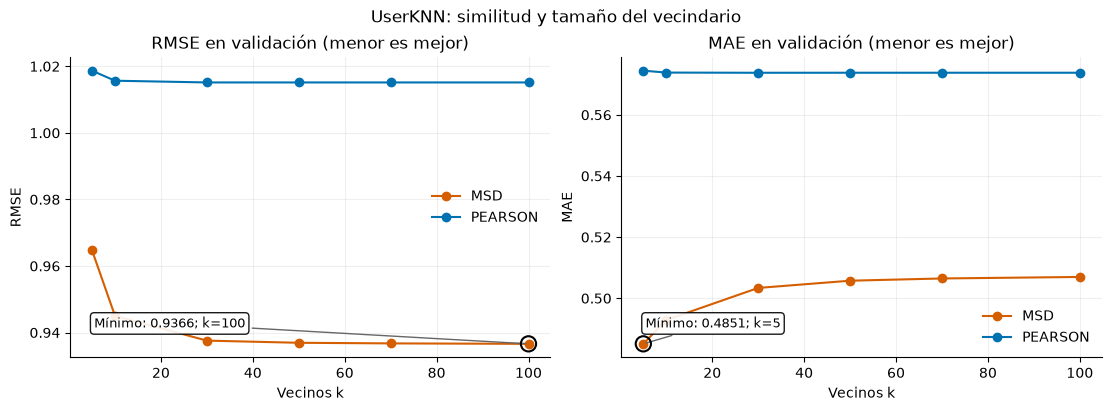

Selección por RMSE: msd, k=100; RMSE=0.936621
Mínimo MAE: msd, k=5; MAE=0.485093
msd: reducción de RMSE entre los extremos de la grilla = 0.028128
pearson: reducción de RMSE entre los extremos de la grilla = 0.003540


In [3]:
fig = plot_user_sensitivity(sensitivity, FIGURES_DIR)
plt.show()

best = sensitivity.loc[sensitivity['is_selected_rmse']].iloc[0]
mae_best = sensitivity.loc[sensitivity['is_selected_mae']].iloc[0]
print(f"Selección por RMSE: {best['similarity']}, k={int(best['k_neighbors'])}; RMSE={best['RMSE']:.6f}")
print(f"Mínimo MAE: {mae_best['similarity']}, k={int(mae_best['k_neighbors'])}; MAE={mae_best['MAE']:.6f}")
for similarity, group in sensitivity.groupby('similarity'):
    group = group.sort_values('k_neighbors')
    delta = group.iloc[0]['RMSE'] - group.iloc[-1]['RMSE']
    print(f'{similarity}: reducción de RMSE entre los extremos de la grilla = {delta:.6f}')

## Ranking Top-10 bajo el protocolo común

Se incluyen todos los ratings reales de validación y hasta 100 ítems no observados por usuario, del catálogo de entrenamiento. La relevancia es `rating >= 4`; los negativos muestreados son no observados, no rechazos comprobados. La semilla y la huella de candidatos se comparten con ItemKNN, FunkSVD y `general.ipynb`.

El ranking usa scores sin recortar y desempate independiente de la etiqueta de relevancia. RMSE/MAE usan exclusivamente ratings reales, con predicciones recortadas a [0,5]. Se conserva `InteractionILD` (disimilitud coseno entre perfiles de interacción) por separado de `TagDiversity` (unión de tags, un proxy que incluye tags no culinarios); la novedad se exporta por ítem y por lista. No se debe llamar a la unión de todos los tags «estilos culinarios» sin definir una taxonomía.

In [4]:
display(experiment['ranking'][[
    'method', 'RMSE', 'MAE', 'Precision@10', 'Recall@10', 'NDCG@10', 'MAP@10',
    'InteractionILD', 'TagDiversity', 'NoveltyBitsPerItem', 'NoveltyBitsPerList', 'CatalogCoverage',
]])
experiment['selection']

,method,RMSE,MAE,Precision@10,Recall@10,NDCG@10,MAP@10,InteractionILD,TagDiversity,NoveltyBitsPerItem,NoveltyBitsPerList,CatalogCoverage
0,UserKNN,0.936621,0.506971,0.033979,0.063145,0.053926,0.025657,0.988574,92.155961,13.385108,133.851075,0.668086


{'method': 'UserKNN',
 'selected_by': 'lowest_validation_rmse',
 'selection_split': 'validation.csv',
 'independent_test': False,
 'params': {'method': 'UserKNN',
  'config_id': 'userknn_msd_k100',
  'k_neighbors': 100,
  'min_k': 1,
  'similarity': 'msd',
  'random_state': 42,
  'status': 'ok',
  'RMSE': 0.9366212697096264,
  'MAE': 0.5069708646260033,
  'similarity_fit_seconds': 0.4413440999924205},
 'protocol': {'protocol_version': 'validation-unseen-v2-raw-score-item-id-ties',
  'ranking_candidate_mode': 'negative_sample_100',
  'k': 10,
  'relevance_threshold': 4.0,
  'n_negatives': 100,
  'seed': 42,
  'sampler': 'numpy.default_rng; sorted users and catalog; without replacement',
  'tie_break': 'score descending, raw item ID ascending',
  'validation_items': 'all observed validation items, including ratings below threshold',
  'unobserved_relevance': 'unknown, treated as zero for offline ranking',
  'accuracy_population': 'macro mean over users with at least one relevant validati

## Interpretación y archivos para el informe

Las curvas permiten distinguir el efecto de la similitud del efecto marginal de aumentar los vecinos. La decisión final debe describir el mínimo observado y la magnitud del cambio, sin afirmar significancia estadística a partir de diferencias pequeñas. La cola larga del EDA motiva contrastar el resultado por actividad de usuario en los archivos de métricas por usuario.

Se guardan `user_based_sensitivity.csv`, `userknn_ranking_metrics.csv`, `userknn_selection.json` y evidencia por usuario/candidatos en `informe_assets/data/`. Las figuras `userknn_sensitivity.png` y `.pdf` tienen textos en español y valores legibles. `general.ipynb` consume esta selección para mantener una sola configuración por familia.